# Exploring the cluster neighbourhood for bulk annotation

Bulk-tagging a cluster of visually similar pages (DINOv2 embeddings + UMAP/HDBSCAN) is efficient
-- "this whole cluster is X, uncheck the exceptions" -- but a single document type rarely lands
cleanly in one cluster. HDBSCAN often splits it across several clusters, especially when its
pages vary in density (scribal hand, ink condition, page wear). Bulk-tagging one cluster and
moving on misses every instance sitting in a neighbouring cluster.

This notebook demonstrates `nearest_cluster_branches` / `describe_cluster_neighbourhood`
(`archival_structures.stream_analysis.overview.cluster_neighbourhood`), which answers "what else
is nearby?" using the *cluster hierarchy itself* -- the condensed tree HDBSCAN builds while
deciding which sub-clusters to keep -- rather than an ad hoc distance in the raw feature space.

Given a query cluster, it walks up the hierarchy and reports, at each step, the nearest sibling
branch: the merge distance, and how many of the currently reported clusters sit inside it. A
branch is often a single cluster, but can be a whole subtree containing several clusters that
split apart again *after* separating from the query -- those clusters merge with the query at
the same tree distance, so the hierarchy alone can't tell them apart. A secondary centroid
distance (`rank_by_centroid_distance`) breaks that tie, ranking same-branch clusters by which one
is actually closest to the query in embedding space.

We apply it to two inventories already used for visual clustering elsewhere in this repo:

- **`NL-HaNA_2.10.50_1`** (scan level) -- a small illustrative example. HDBSCAN finds only 3
  clusters here, which makes the tree-walk mechanics easy to follow step by step.
- **`NL-AsnDA_0114.11_1`** (page level, verso/recto split) -- a realistic case where the
  running-text pages of the notary deeds fragment across more than a dozen clusters, giving a
  concrete "explore the neighbourhood to find the rest of this document type" scenario.


In [1]:
from pathlib import Path
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import umap
import hdbscan
import pagexml.parser as pagexml_parser

from archival_structures.analysis.opening_detection import (
    compute_corpus_median_width, is_opening, get_opening_features, split_scan,
)
from archival_structures.stream_analysis import (
    nearest_cluster_branches,
    describe_cluster_neighbourhood,
    format_cluster_neighbourhood,
)

REPO_ROOT = Path('../../../')
DATA_ROOT = REPO_ROOT / 'data'


In [2]:
def show_thumbnail_grid(images, titles=None, cols=6, cell_w=1.5, cell_h=1.9):
    """Plot a grid of already-loaded PIL images, e.g. one cluster's members."""
    n = len(images)
    if n == 0:
        print('(no images)')
        return
    rows = -(-n // cols)  # ceil division
    fig, axes = plt.subplots(rows, cols, figsize=(cols * cell_w, rows * cell_h))
    axes = np.atleast_1d(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis('off')
        if i < n:
            ax.imshow(images[i])
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    plt.tight_layout()
    plt.show()


---
## Part 1: a small illustrative example -- `NL-HaNA_2.10.50_1`

DINOv2 embeddings have been pre-computed and cached for this inventory's 336 scans (see
`cluster-sequence-analysis-demo.ipynb`). We cluster them directly (UMAP + HDBSCAN) and get a
simple 3-cluster result: a large dominant cluster of table-register pages, and two small
clusters that turn out to be different kinds of title/section-opening pages.


In [3]:
EMBS_DIR = DATA_ROOT / 'stream_analysis/NL-HaNA/NL-HaNA_2.10.50/1'
THUMB_DIR_2105 = DATA_ROOT / 'thumbs/NL-HaNA/NL-HaNA_2.10.50/NL-HaNA_2.10.50_1'

emb_2105 = np.load(EMBS_DIR / 'embeddings.npy')
with open(EMBS_DIR / 'image_ids.json') as f:
    image_ids_2105 = [Path(p).name for p in json.load(f)]

print(f'Embeddings: {emb_2105.shape}   ({len(image_ids_2105)} scans)')


Embeddings: (336, 768)   (336 scans)


In [4]:
reducer_2105 = umap.UMAP(n_components=10, n_neighbors=15, metric='cosine', random_state=42)
umap_2105 = reducer_2105.fit_transform(emb_2105)

clusterer_2105 = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=2)
clusterer_2105.fit(umap_2105)
labels_2105 = clusterer_2105.labels_

print('Cluster distribution:', sorted(Counter(labels_2105.tolist()).items()))


/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Cluster distribution: [(0, 320), (1, 5), (2, 11)]


### Walking the tree from each cluster

For every cluster, `describe_cluster_neighbourhood` reports the nearest branch(es) by increasing
tree distance. With only 3 clusters, each walk has at most 2 steps -- but the pattern already
shows the two things to look for: a single-cluster branch, and the fact that distances make the
overall structure explicit (clusters 1 and 2 are much closer to each other than either is to the
dominant cluster 0).


In [5]:
for query_label in sorted(set(labels_2105.tolist()) - {-1}):
    print(f'--- nearest branches to cluster {query_label} '
          f'(n={int((labels_2105 == query_label).sum())}) ---')
    branches = describe_cluster_neighbourhood(
        query_label, clusterer_2105.condensed_tree_, umap_2105, labels_2105, top_n=5,
    )
    print(format_cluster_neighbourhood(branches).to_string(index=False))
    print()


--- nearest branches to cluster 0 (n=320) ---
 rank  distance  n_clusters  n_points               clusters
    1     4.054           2        16 1 (Δ=6.12), 2 (Δ=6.62)

--- nearest branches to cluster 1 (n=5) ---
 rank  distance  n_clusters  n_points   clusters
    1     0.345           1        11 2 (Δ=0.63)
    2     4.054           1       320 0 (Δ=6.12)

--- nearest branches to cluster 2 (n=11) ---
 rank  distance  n_clusters  n_points   clusters
    1     0.345           1         5 1 (Δ=0.63)
    2     4.054           1       320 0 (Δ=6.62)



Cluster 0 (the 320 table-register pages) only merges with the rest at a much larger distance
than clusters 1 and 2 merge with each other -- confirming that 1 and 2, despite being separate
HDBSCAN clusters, are far more similar to each other than either is to the dominant cluster. A
quick visual check below confirms this: clusters 1 and 2 both show single, sparsely-filled
section-opening pages, distinct from the dense two-column tables in cluster 0.


Cluster 0 (320 scans) -- showing 6:


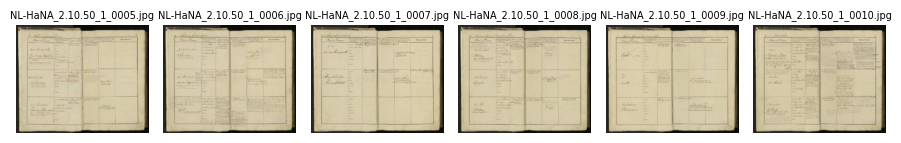

Cluster 1 (5 scans) -- showing 5:


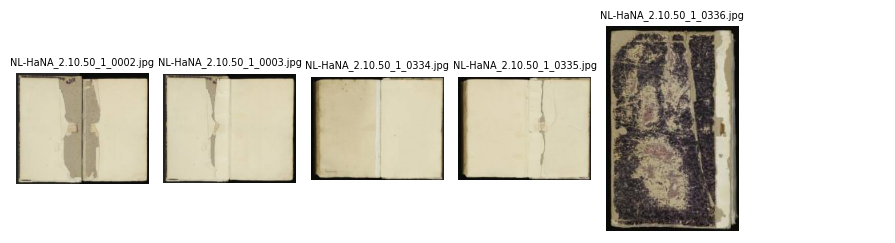

Cluster 2 (11 scans) -- showing 6:


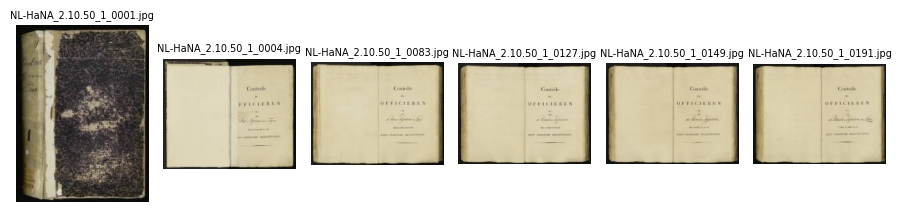

In [6]:
for query_label in sorted(set(labels_2105.tolist()) - {-1}):
    scan_ids = [image_ids_2105[i] for i in range(len(image_ids_2105)) if labels_2105[i] == query_label]
    sample = scan_ids[:6]
    images = [Image.open(THUMB_DIR_2105 / scan_id).convert('RGB') for scan_id in sample]
    print(f'Cluster {query_label} ({len(scan_ids)} scans) -- showing {len(sample)}:')
    show_thumbnail_grid(images, titles=sample, cols=6, cell_h=2.4)


---
## Part 2: a realistic case -- `NL-AsnDA_0114.11_1`

This inventory is split into individual verso/recto pages (opening detection), giving 1258 pages
in total. DINOv2 embeddings for these pages are already cached (see
`cluster-sequence-analysis-demo.ipynb`), so we load them directly rather than recomputing.


In [7]:
PXD_ASDA = DATA_ROOT / 'PageXML/NL-AsnDA/NL-AsnDA_0114.11/NL-AsnDA_0114.11_1'
THUMB_DIR_ASDA = DATA_ROOT / 'thumbs/NL-AsnDA/NL-AsnDA_0114.11/NL-AsnDA_0114.11_1'
EMB_CACHE_ASDA = DATA_ROOT / 'stream_analysis/NL-AsnDA/NL-AsnDA_0114.11/1/page_embeddings.npy'

xml_files_asda = sorted(PXD_ASDA.glob('*.xml'))
scans_asda = [pagexml_parser.parse_pagexml_file(str(p)) for p in xml_files_asda]
median_w_asda = compute_corpus_median_width(scans_asda)
print(f'{len(scans_asda)} scans, corpus median width {median_w_asda:.0f}px')


630 scans, corpus median width 4993px


In [8]:
def thumb_fn_asda(scan_id: str) -> str:
    return f'thumb-width_300-scan-{scan_id.replace(".jpg", ".jp2")}.png'


def load_page_image(scan_id: str, side: str, thumb_dir: Path) -> Image.Image:
    img = Image.open(thumb_dir / thumb_fn_asda(scan_id)).convert('RGB')
    if side == 'full':
        return img
    mid = img.width // 2
    return img.crop((0, 0, mid, img.height)) if side == 'verso' else img.crop((mid, 0, img.width, img.height))


# Re-derive page_keys in the same order used when the cached embeddings were computed --
# cheap (no DINOv2 inference needed), since the embeddings themselves are already cached.
page_keys_asda = []
for scan in scans_asda:
    if not (THUMB_DIR_ASDA / thumb_fn_asda(scan.id)).exists():
        continue
    if scan.coords.w >= 0.85 * median_w_asda:
        page_keys_asda.append((scan.id, 'verso'))
        page_keys_asda.append((scan.id, 'recto'))
    else:
        page_keys_asda.append((scan.id, 'full'))

emb_asda = np.load(EMB_CACHE_ASDA)
assert emb_asda.shape[0] == len(page_keys_asda), (emb_asda.shape, len(page_keys_asda))
print(f'Page embeddings: {emb_asda.shape}   ({len(page_keys_asda)} pages)')


Page embeddings: (1258, 768)   (1258 pages)


### Clustering with a smaller `min_cluster_size` than the sequence-analysis demo

`cluster-sequence-analysis-demo.ipynb` used `min_cluster_size=20` to get a clean 5-cluster split
(mainly separating blank rectos from running text) for sequence-pattern mining. Here we use a
smaller `min_cluster_size=15` on purpose: it fragments the running-text pages into more than a
dozen clusters -- exactly the "one document type spread across several clusters" scenario bulk
annotation runs into in practice.


In [9]:
reducer_asda = umap.UMAP(n_components=10, n_neighbors=15, metric='cosine', random_state=42)
umap_asda = reducer_asda.fit_transform(emb_asda)

clusterer_asda = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=4)
clusterer_asda.fit(umap_asda)
labels_asda = clusterer_asda.labels_

print(f'{labels_asda.max() + 1} clusters, {int((labels_asda == -1).sum())} noise points '
      f'({(labels_asda == -1).sum() / len(labels_asda):.0%})')
print(sorted(Counter(labels_asda.tolist()).items()))


/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


17 clusters, 261 noise points (21%)
[(-1, 261), (0, 325), (1, 24), (2, 28), (3, 25), (4, 24), (5, 21), (6, 85), (7, 23), (8, 18), (9, 73), (10, 35), (11, 28), (12, 70), (13, 50), (14, 47), (15, 63), (16, 58)]


Cluster 0 (325 pages) is the blank-recto cluster identified in `cluster-sequence-analysis-demo.ipynb`.
Everything else is running text, now fragmented into more than a dozen clusters of varying size --
a realistic bulk-annotation starting point: pick one of these clusters and find the rest.


In [10]:
QUERY_LABEL = 6  # a mid-sized text cluster -- picked after inspecting the distribution above
print(f'Query cluster {QUERY_LABEL}: {int((labels_asda == QUERY_LABEL).sum())} pages')

branches_asda = describe_cluster_neighbourhood(
    QUERY_LABEL, clusterer_asda.condensed_tree_, umap_asda, labels_asda, top_n=7,
)
format_cluster_neighbourhood(branches_asda)


Query cluster 6: 85 pages


,rank,distance,n_clusters,n_points,clusters
0,1,0.414,6,441,"8 (Δ=1.56), 13 (Δ=2.26), 16 (Δ=2.39), 9 (Δ=2.4..."
1,2,0.415,4,199,"7 (Δ=3.27), 10 (Δ=4.17), 12 (Δ=5.43), 11 (Δ=6.93)"
2,3,0.430,2,46,"5 (Δ=2.30), 4 (Δ=3.72)"
3,4,0.678,1,25,3 (Δ=5.06)
4,5,0.687,1,28,2 (Δ=3.49)
5,6,1.669,1,24,1 (Δ=3.83)
6,7,1.959,1,325,0 (Δ=11.32)


The first two branches are each a *group* of several clusters merging with the query at nearly
the same (small) distance -- these are the other running-text fragments. Only several steps
later, at a distance roughly 3-4x larger, does cluster 0 (the blank-recto cluster) appear --
exactly where a bulk-annotation session should stop extending the running-text tag.

Within a multi-cluster branch, `ranked_clusters` (used to build the `clusters` column above)
orders the individual clusters by centroid distance to the query -- since the tree alone reports
them as tied, this is the tie-breaker that tells you which one to check first.


Branch 1 (distance=0.41) -- cluster 8 (Δ=1.56 from query, 18 pages total):


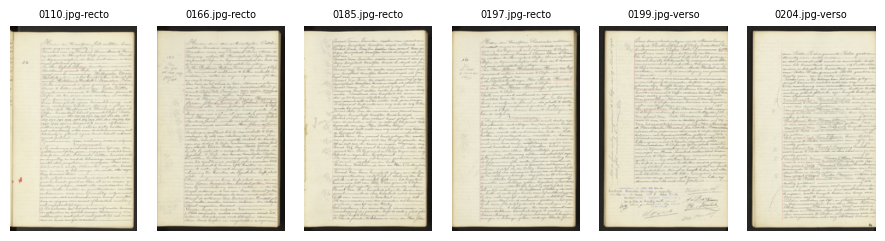

Branch 1 (distance=0.41) -- cluster 13 (Δ=2.26 from query, 50 pages total):


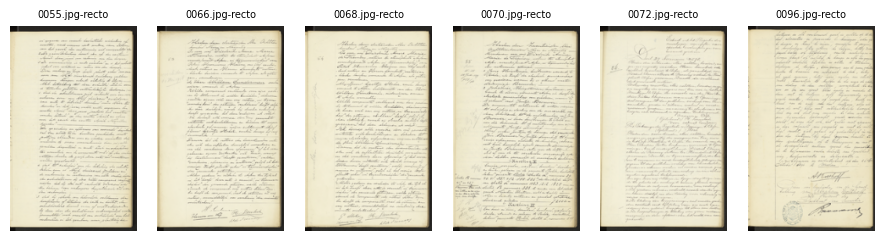

Branch 1 (distance=0.41) -- cluster 16 (Δ=2.39 from query, 58 pages total):


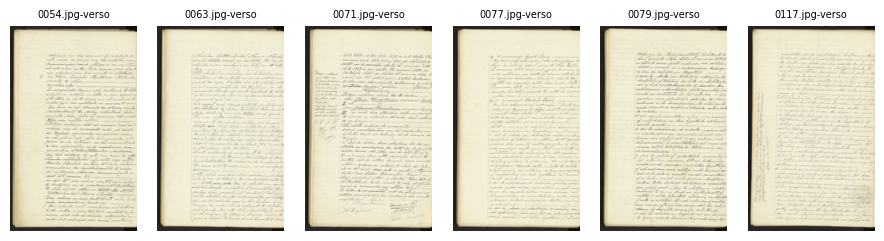

Branch 1 (distance=0.41) -- cluster 9 (Δ=2.40 from query, 73 pages total):


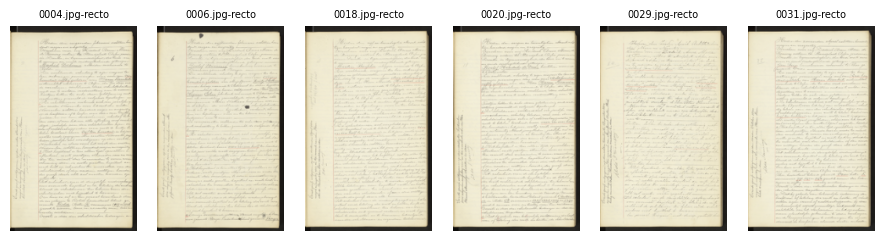

Branch 1 (distance=0.41) -- cluster 14 (Δ=2.65 from query, 47 pages total):


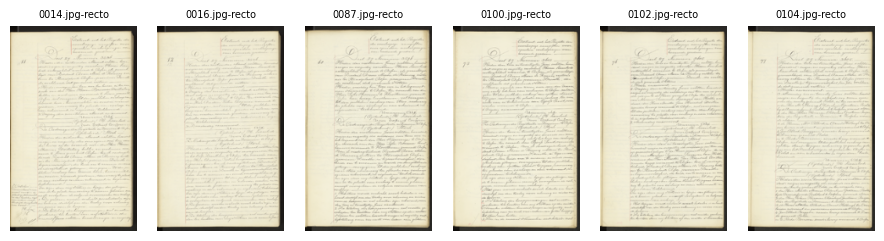

Branch 1 (distance=0.41) -- cluster 15 (Δ=2.67 from query, 63 pages total):


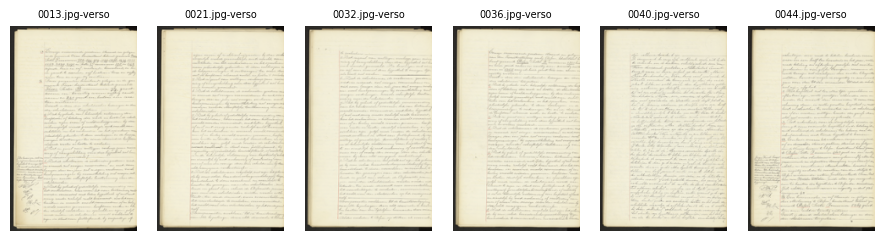

Branch 2 (distance=0.42) -- cluster 7 (Δ=3.27 from query, 23 pages total):


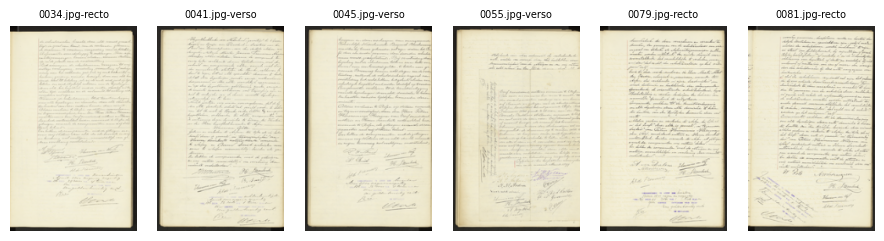

Branch 2 (distance=0.42) -- cluster 10 (Δ=4.17 from query, 35 pages total):


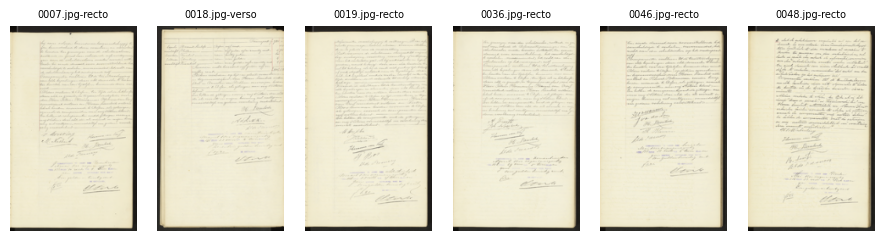

Branch 2 (distance=0.42) -- cluster 12 (Δ=5.43 from query, 70 pages total):


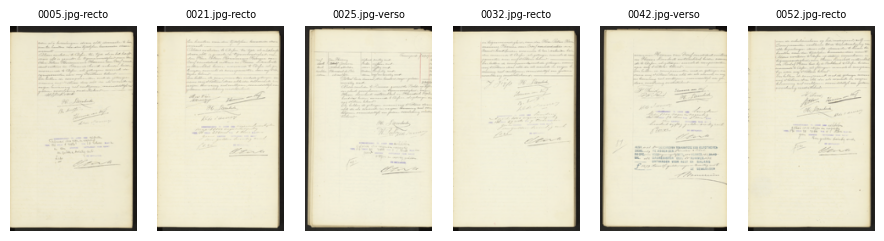

Branch 2 (distance=0.42) -- cluster 11 (Δ=6.93 from query, 28 pages total):


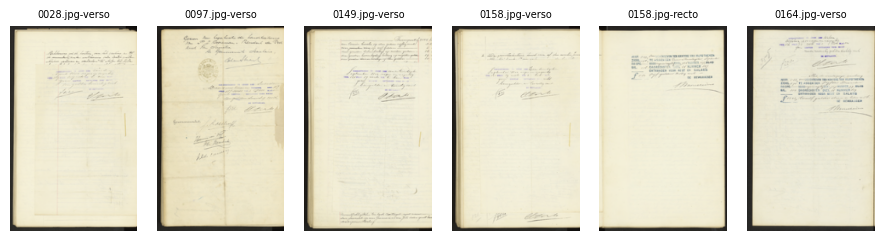

Branch 3 (distance=0.43) -- cluster 5 (Δ=2.30 from query, 21 pages total):


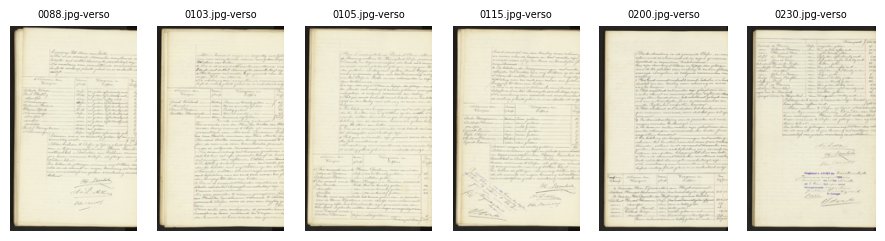

Branch 3 (distance=0.43) -- cluster 4 (Δ=3.72 from query, 24 pages total):


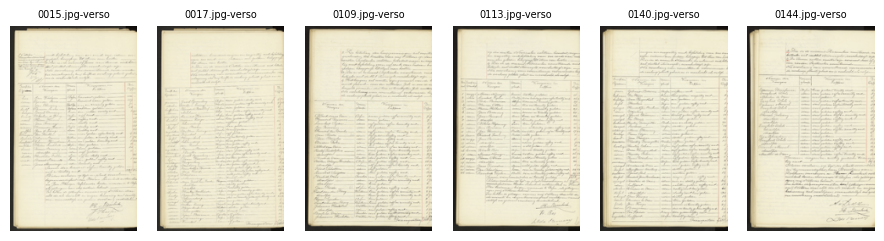

In [11]:
# Visually confirm: the query cluster and its two nearest branches should all show
# running body-text pages, distinct from the blank-recto cluster reached much later.
def sample_pages(label, labels, page_keys, n=6):
    indices = [i for i, l in enumerate(labels) if l == label][:n]
    return [page_keys[i] for i in indices]


for branch_rank, branch in enumerate(branches_asda[:3], start=1):
    for cluster_label, centroid_dist in branch['ranked_clusters']:
        sample = sample_pages(cluster_label, labels_asda, page_keys_asda)
        images = [load_page_image(scan_id, side, THUMB_DIR_ASDA) for scan_id, side in sample]
        titles = [f'{scan_id.split("_")[-1]}-{side}' for scan_id, side in sample]
        n_total = int((labels_asda == cluster_label).sum())
        print(f'Branch {branch_rank} (distance={branch["distance"]:.2f}) -- '
              f'cluster {cluster_label} (Δ={centroid_dist:.2f} from query, {n_total} pages total):')
        show_thumbnail_grid(images, titles=titles, cols=6, cell_h=2.4)


For comparison, cluster 0 (blank rectos, reached last, distance=1.96):


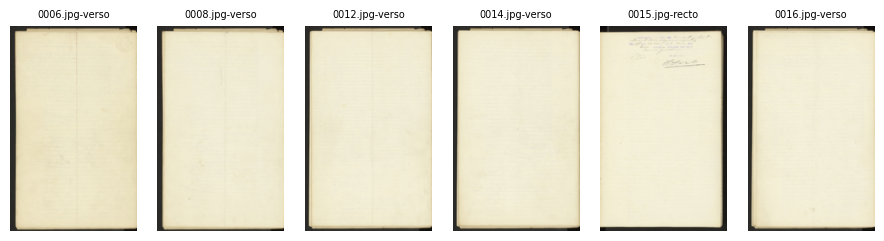

In [12]:
print(f'For comparison, cluster 0 (blank rectos, reached last, distance='
      f'{branches_asda[-1]["distance"]:.2f}):')
sample_blank = sample_pages(0, labels_asda, page_keys_asda)
images_blank = [load_page_image(scan_id, side, THUMB_DIR_ASDA) for scan_id, side in sample_blank]
titles_blank = [f'{scan_id.split("_")[-1]}-{side}' for scan_id, side in sample_blank]
show_thumbnail_grid(images_blank, titles=titles_blank, cols=6, cell_h=2.4)


---
## From exploration to bulk tagging

Once a stopping point is chosen (here: everything up to, but not including, the blank-recto
cluster), the merged set of scan/page ids is exactly the `image_ids` argument
`archival_structures.datasets.bulk_tagging.annotate_image_grid_with_tags` expects.

For scan-level clustering (`NL-HaNA_2.10.50_1` above), thumbnail paths are a direct join against
`THUMB_DIR` -- so `annotate_image_grid_with_tags` can tag the merged cluster set directly. For
page-level clustering (`NL-AsnDA_0114.11_1`, split into verso/recto), tagging happens at the
underlying *scan*, not the half-page, since `ScanAnnotation` records apply to a whole scan -- so
the page keys need de-duplicating back to scan ids first (a verso and its recto share one
thumbnail file and one scan-level annotation record).


In [13]:
# Example: merge the query cluster with its two nearest branches (still excluding the
# blank-recto cluster), then collapse page keys back to unique scan thumbnail paths.
merged_labels = {QUERY_LABEL} | {c for b in branches_asda[:2] for c in b['cluster_labels']}
print(f'Merged clusters: {sorted(merged_labels)}')

merged_scan_ids = sorted({
    scan_id for (scan_id, _side), label in zip(page_keys_asda, labels_asda) if label in merged_labels
})
print(f'{len(merged_scan_ids)} unique scans covering the merged clusters')

image_ids_for_tagging = [str(THUMB_DIR_ASDA / thumb_fn_asda(scan_id)) for scan_id in merged_scan_ids]
image_ids_for_tagging[:3]


Merged clusters: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
414 unique scans covering the merged clusters


['../../../data/thumbs/NL-AsnDA/NL-AsnDA_0114.11/NL-AsnDA_0114.11_1/thumb-width_300-scan-NL-AsnDA_0114.11_1_0004.jp2.png',
 '../../../data/thumbs/NL-AsnDA/NL-AsnDA_0114.11/NL-AsnDA_0114.11_1/thumb-width_300-scan-NL-AsnDA_0114.11_1_0005.jp2.png',
 '../../../data/thumbs/NL-AsnDA/NL-AsnDA_0114.11/NL-AsnDA_0114.11_1/thumb-width_300-scan-NL-AsnDA_0114.11_1_0006.jp2.png']

`annotate_image_grid_with_tags(image_ids_for_tagging, ...)` would open the paginated,
checkbox-selectable tagging grid over exactly this merged set -- see
`bulk-tag-annotation-demo.ipynb` for the full tagging workflow. It isn't called here so this
notebook can run end-to-end without leaving annotation state behind on every execution; wire it
in directly when doing the tagging for real.


## Summary

- `nearest_cluster_branches` walks the HDBSCAN condensed tree from a query cluster and reports
  the nearest sibling branch(es) at each step, ordered by tree distance -- using the same
  density-based hierarchy HDBSCAN already computed, rather than an ad hoc distance measure.
- A branch is either a single cluster or a subtree containing several clusters that merge with
  the query at the same tree distance; `rank_by_centroid_distance` (bundled by
  `describe_cluster_neighbourhood`) breaks that tie using Euclidean centroid distance in
  embedding space.
- On `NL-HaNA_2.10.50_1`, the 3-cluster result makes the walk trivial to follow and confirms
  that two small "title-like" clusters are much closer to each other than to the dominant table
  cluster.
- On `NL-AsnDA_0114.11_1`, a deliberately fragmented clustering (`min_cluster_size=15`) splits
  the running-text pages across more than a dozen clusters; walking from one of them recovers
  the rest at small distances, while the unrelated blank-recto cluster only appears much later --
  giving a concrete, visually-confirmed stopping condition for a bulk-annotation session.
